# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import ShipsInGoogleEarthDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 794


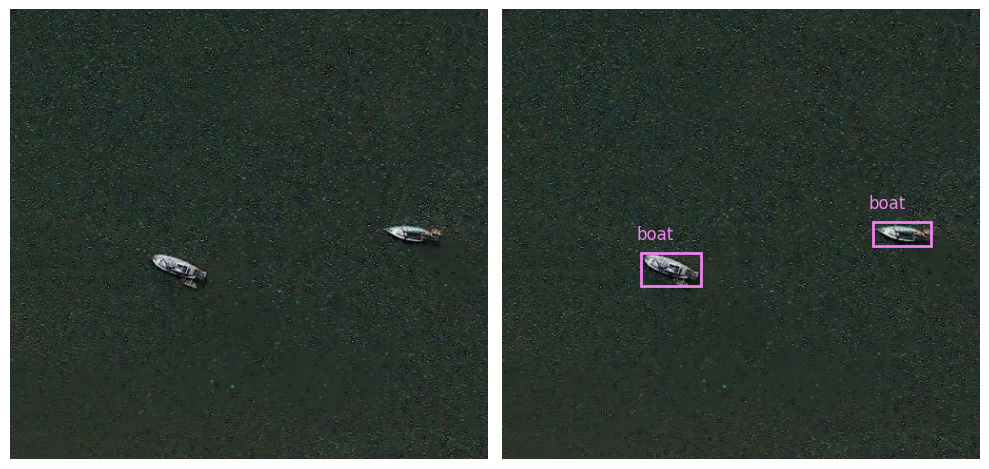

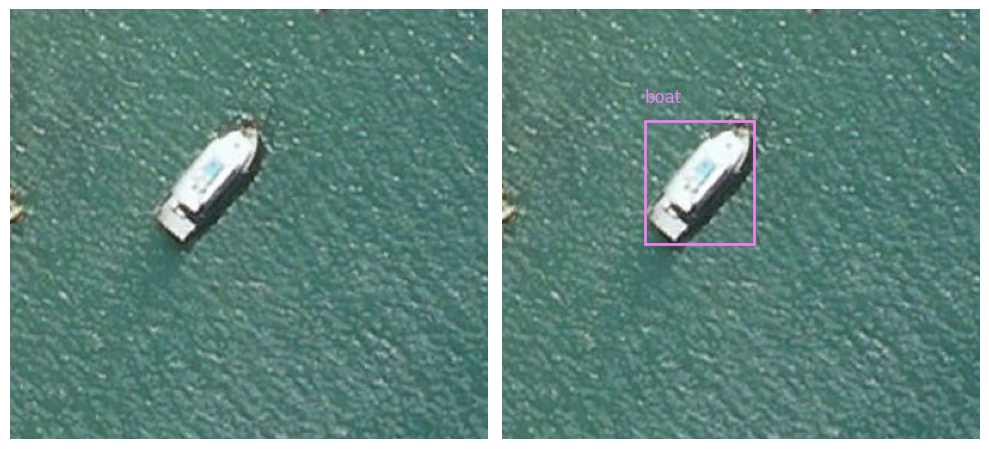

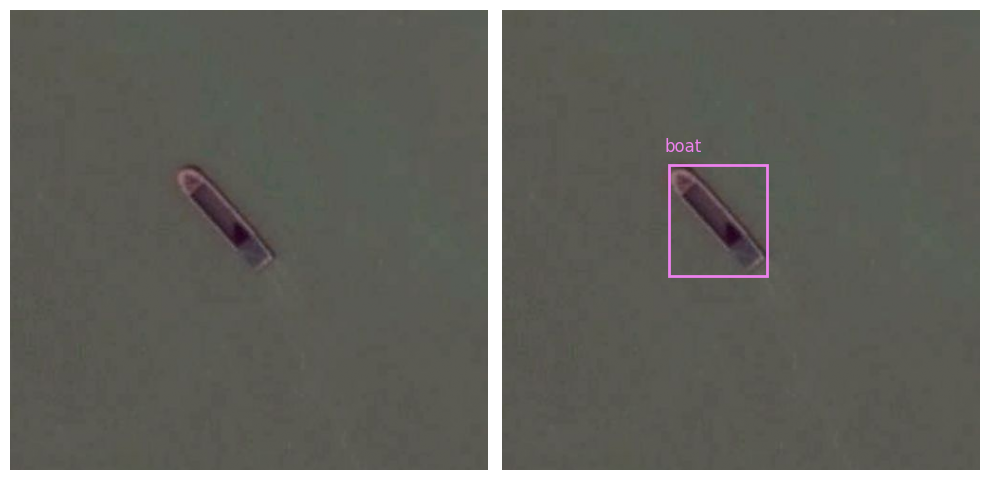

In [ ]:
dataset_config = {
    "image_dir": "./data/ships_in_google_earth/JPEGImages/",
    "annotations_dir": "./data/ships_in_google_earth/annotations/",
}
dataset = ShipsInGoogleEarthDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

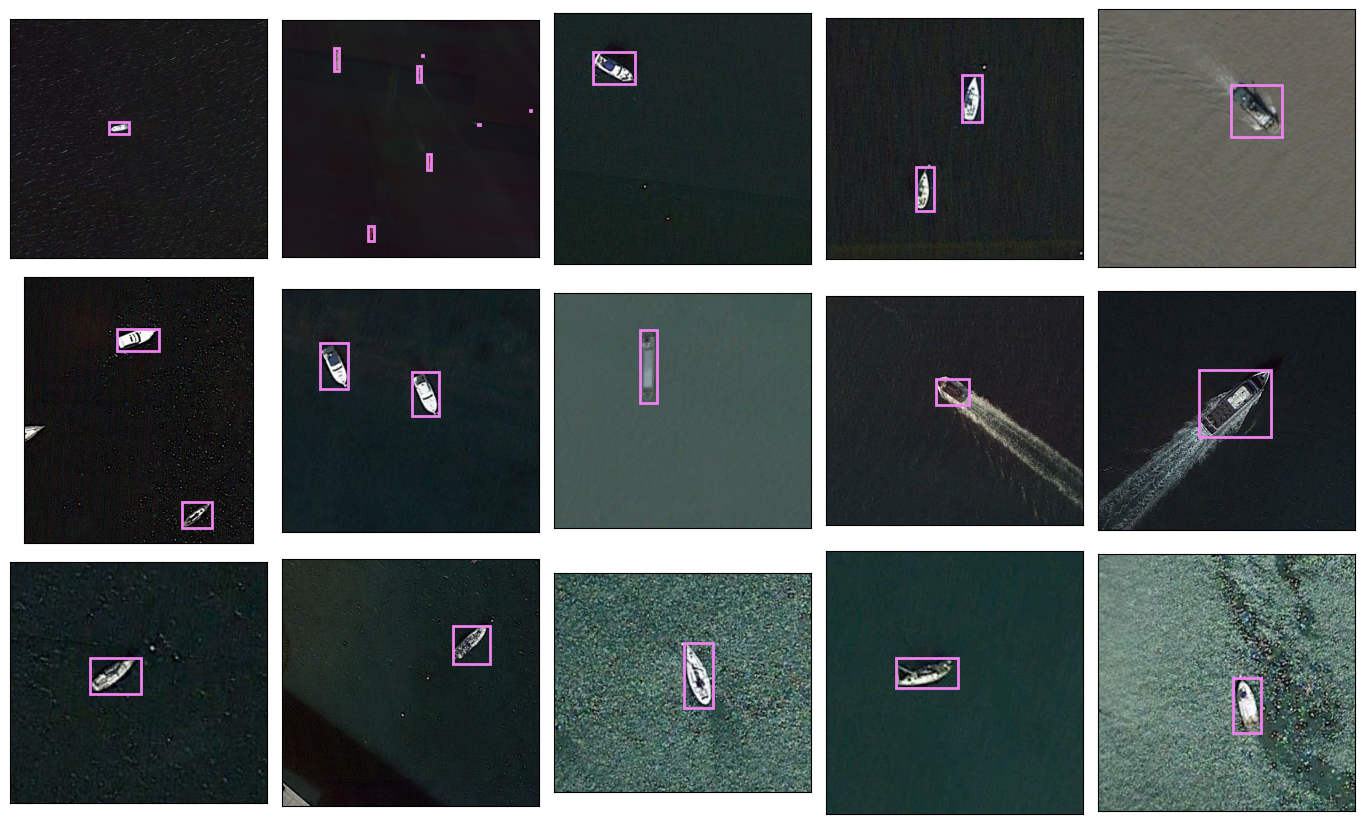

In [8]:
dataset.show_batch(15);

In [9]:
dataset.data_distribution_table()

,Label,Count
0,boat,2025


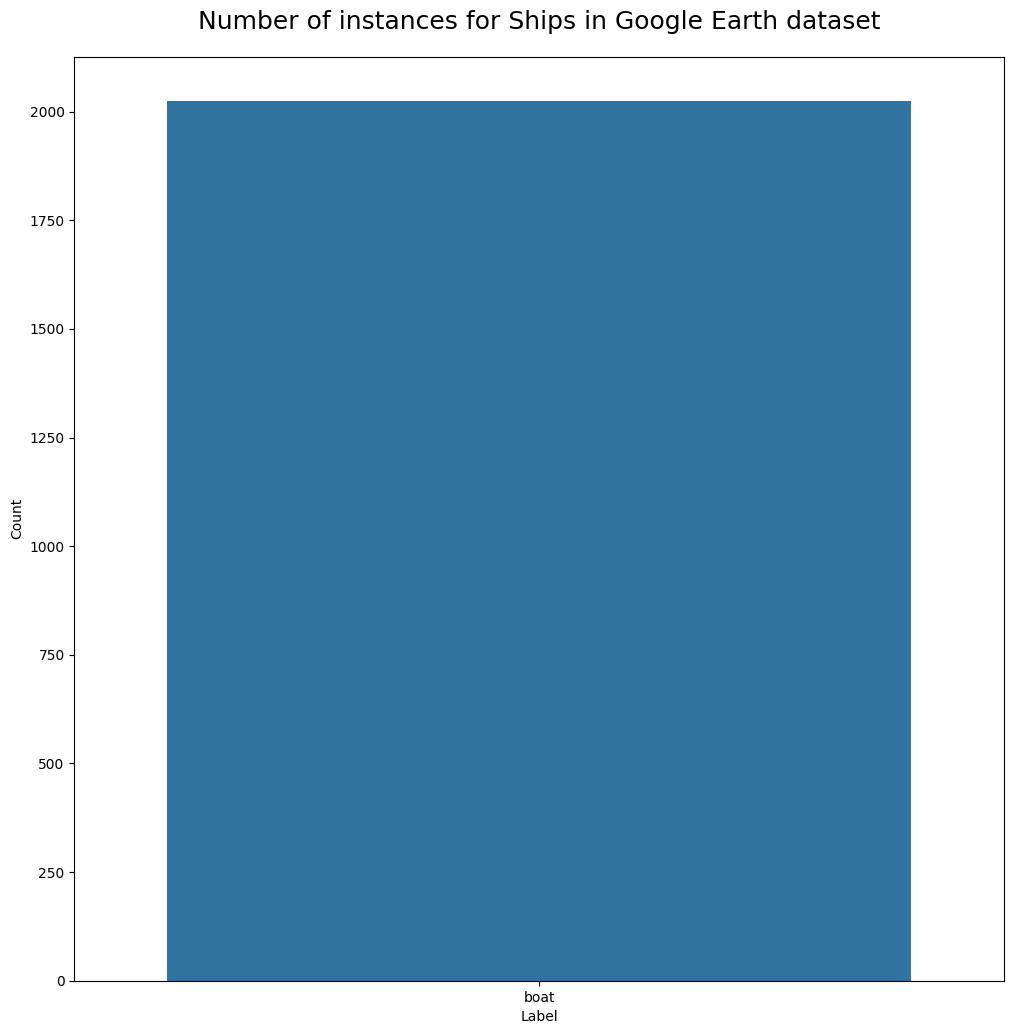

In [10]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "image_dir": "./data/ships_in_google_earth/training/JPEGImages/",
    "annotations_dir": "./data/ships_in_google_earth/training/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = ShipsInGoogleEarthDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 694


## Create the model

In [ ]:
epochs = 20
model_directory = "./data/ships_in_google_earth/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [22]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 09:28:03,038 INFO Starting training.
training: 100%|██████████| 87/87 [00:28<00:00,  3.09it/s]
2025-05-22 09:28:31,198 INFO epoch: 1, time: 28, loss:  0.19466
testing on train set: 100%|██████████| 87/87 [00:15<00:00,  5.78it/s]
2025-05-22 09:28:49,797 INFO map:0.5652635097503662, map_50:0.8148742914199829, map_75:0.6706907749176025, map_small:0.38715362548828125, map_medium:0.7480935454368591, map_large:0.8132045865058899, mar_1:0.29930630326271057, mar_10:0.45987191796302795, mar_100:0.6120597720146179, mar_small:0.44795820116996765, mar_medium:0.8035335540771484, mar_large:0.8647058606147766, map_per_class:0.5652635097503662, mar_100_per_class:0.6120597720146179, classes:1.0
training: 100%|██████████| 87/87 [00:28<00:00,  3.02it/s]
2025-05-22 09:29:18,646 INFO epoch: 2, time: 29, loss:  0.10215
testing on train set: 100%|██████████| 87/87 [00:15<00:00,  5.65it/s]
2025-05-22 09:29:36,123 INFO map:0.5626858472824097, map_50:0.8577150106430054, map_75:0.6488933563232422, map

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "./data/ships_in_google_earth/test/JPEGImages/",
    "annotations_dir": "./data/ships_in_google_earth/test/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = ShipsInGoogleEarthDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/ships_in_google_earth/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 100


2025-05-22 09:43:21,675 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ships_in_google_earth/experiments/checkpoint.pth.tar
2025-05-22 09:43:21,993 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ships_in_google_earth/experiments/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 13/13 [00:02<00:00,  5.07it/s]


[{'map': 0.6823838949203491,
  'map_50': 0.9644660353660583,
  'map_75': 0.8214893341064453,
  'map_small': 0.4000982344150543,
  'map_medium': 0.7183236479759216,
  'map_large': 0.8876944780349731,
  'mar_1': 0.4841059744358063,
  'mar_10': 0.7238410711288452,
  'mar_100': 0.7238410711288452,
  'mar_small': 0.4952380955219269,
  'mar_medium': 0.7487603425979614,
  'mar_large': 0.9222221970558167,
  'map_per_class': 0.6823838949203491,
  'mar_100_per_class': 0.7238410711288452,
  'classes': 1.0}]

## Predictions

2025-05-22 09:43:35,988 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ships_in_google_earth/experiments/checkpoint.pth.tar
2025-05-22 09:43:36,315 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ships_in_google_earth/experiments/checkpoint.pth.tar at epoch 21


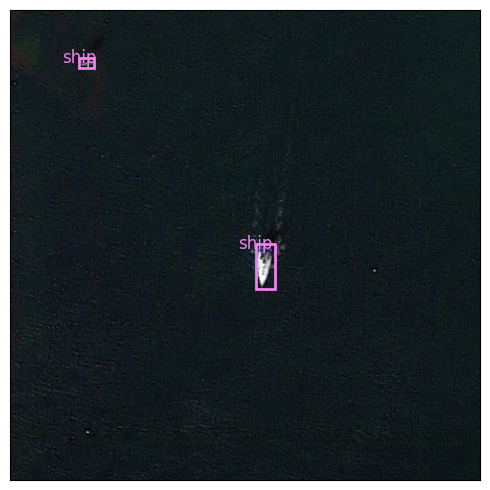

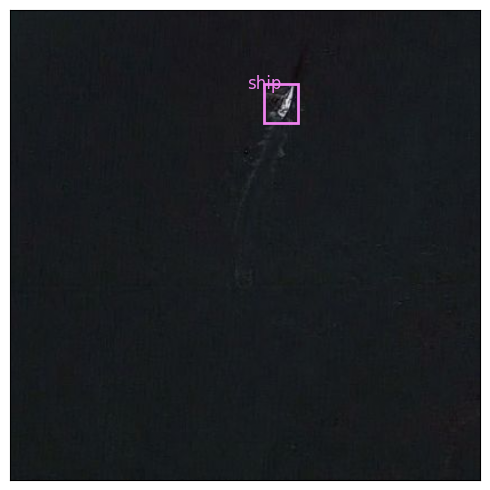

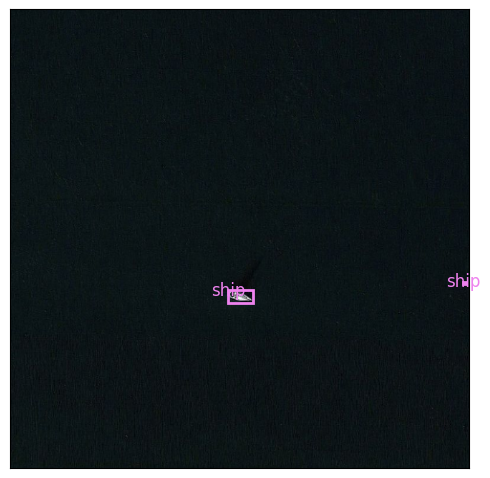

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/ships_in_google_earth/experiments/checkpoint.pth.tar"
labels = ['no-data','ship']
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/ships_in_google_earth/test/JPEGImages/Test9.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ships_in_google_earth/test/JPEGImages/Test15.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/ships_in_google_earth/test/JPEGImages/Test20.jpg')
fig = model.detect_objects(image, labels, transform)